# 07. GAN (생성적 적대 신경망, Generative Adversarial Network)

## 🎯 이 노트북에서 배울 것
1. **생성자(Generator) vs 판별자(Discriminator)**의 minmax 게임 원리
2. 2D "8개 가우시안이 고리 모양으로 놓인" 분포를 GAN이 **스스로 만들어내는 과정**을 눈으로 확인
3. 학습 팁: 로짓 출력 + `BCEWithLogitsLoss`, `detach()`, 적은 학습률

## 📖 핵심 개념
- 생성자 G: 노이즈 z ~ N(0, I)에서 시작해 **가짜 데이터 G(z)**를 만듦
- 판별자 D: 입력이 "진짜 데이터"인지 "G가 만든 가짜"인지 확률로 판별
- minmax 목적함수: `min_G max_D  E[log D(x)] + E[log(1 − D(G(z)))]`
- 학습: D와 G를 번갈아 가며 각각의 손실을 최소화 (적대적 경쟁 → G가 점점 진짜 같은 샘플 생성)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록, 환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (6, 6)


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47785 (\N{HANGUL SYLLABLE MOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54364 (\N{HANGUL SYLLABLE PYO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

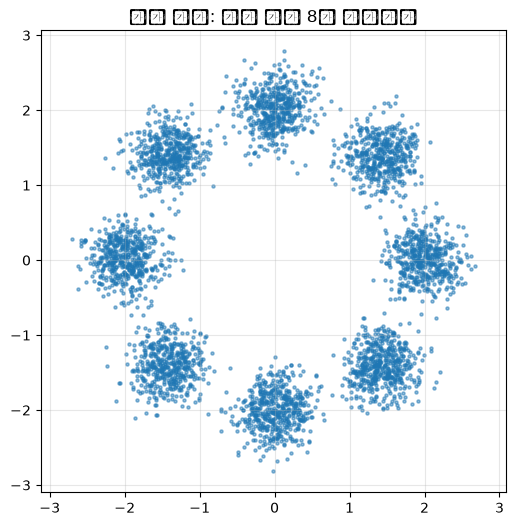

In [2]:
# 데이터: 반지름 2인 원 위에 8개의 가우시안 (각 σ=0.25)
n_data = 4000
angles = np.linspace(0, 2 * np.pi, 8, endpoint=False)
centers = np.column_stack([2.0 * np.cos(angles), 2.0 * np.sin(angles)])
idx = rng.integers(0, 8, n_data)
data = centers[idx] + rng.normal(0, 0.25, (n_data, 2))

plt.scatter(data[:, 0], data[:, 1], s=5, alpha=0.5)
plt.title("목표 분포: 고리 위의 8개 가우시안"); plt.axis("equal"); plt.grid(alpha=0.3); plt.show()


## 1) 생성자와 판별자 정의

- **생성자**: 2차원 노이즈 z → MLP → 2차원 좌표 (출력에 tanh 없이 선형: 데이터 범위가 −3~3이라 огранич할 필요 없음)
- **판별자**: 2차원 좌표 → MLP → **로짓 1개** (마지막에 시그모이드를 거는 것보다 `BCEWithLogitsLoss`가 수치적으로 안정적)


In [3]:
import torch
import torch.nn as nn

torch.manual_seed(0)
data_t = torch.tensor(data, dtype=torch.float32)

class Generator(nn.Module):
    def __init__(self, z_dim=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 64), nn.LeakyReLU(0.2),   # LeakyReLU: 음수 영역에서도 기울기 있음 →기울기 소실 방지
            nn.Linear(64, 64), nn.LeakyReLU(0.2),
            nn.Linear(64, 2),                          # 출력: 2차원 좌표 (선형)
        )
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.LeakyReLU(0.2),
            nn.Linear(64, 64), nn.LeakyReLU(0.2),
            nn.Linear(64, 1),                          # 로짓 1개 출력 (시그모이드는 손실 함수에 포함)
        )
    def forward(self, x):
        return self.net(x)

G = Generator()
D = Discriminator()
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))  # GAN은 betas=(0.5, 0.999)가 안정적
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()   # 로짓 + 시그모이드 + BCE를 수치적으로 안정되게 하나로 합친 것


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

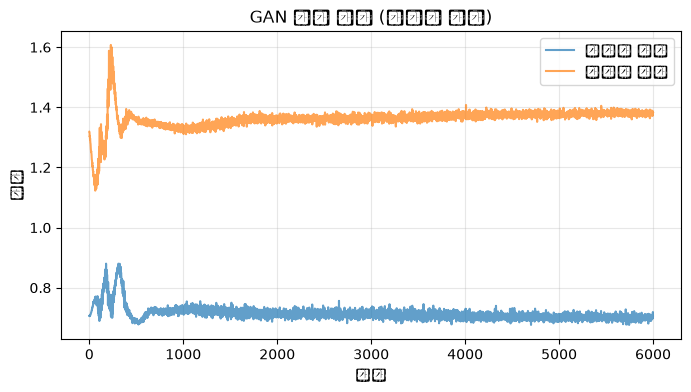

In [4]:
# 2) 적대적 학습 루프
snapshots = {}      # 학습도중의 생성 샘플을 저장해서 변화 과정을 볼 것
g_losses, d_losses = [], []
ITERS = 6000
BATCH = 128

for it in range(ITERS):
    # ── (1) 판별자 D 학습: 진짜는 1, 가짜는 0으로 판별하도록 ──
    real = data_t[rng.integers(0, n_data, BATCH)]      # 실제 데이터 미니배치
    z = torch.randn(BATCH, 2)                          # 가우시안 노이즈
    fake = G(z).detach()   # detach(): 판별자 학습 시 생성자의 가중치는 갱신하지 않음 (역전파 차단)
    d_loss = bce(D(real), torch.ones(BATCH, 1)) + bce(D(fake), torch.zeros(BATCH, 1))
    optD.zero_grad(); d_loss.backward(); optD.step()

    # ── (2) 생성자 G 학습: 가짜 샘플을 '진짜(1)'라고 속이도록 ──
    z = torch.randn(BATCH, 2)
    g_loss = bce(D(G(z)), torch.ones(BATCH, 1))        # D가 가짜를 진짜로 착각하게 만드는 것이 목표
    optG.zero_grad(); g_loss.backward(); optG.step()

    g_losses.append(g_loss.item()); d_losses.append(d_loss.item())
    if it in (0, 1000, 3000, ITERS - 1):
        with torch.no_grad():
            snapshots[it] = G(torch.randn(500, 2)).numpy()

plt.figure(figsize=(8, 4))
plt.plot(g_losses, label="생성자 손실", alpha=0.7)
plt.plot(d_losses, label="판별자 손실", alpha=0.7)
plt.xlabel("반복"); plt.ylabel("손실"); plt.title("GAN 학습 곡선 (적대적 균형)")
plt.legend(); plt.grid(alpha=0.3); plt.show()


## 3) 학습과정중 생성 샘플이 어떻게 변하는지 확인

반복 0 → 1000 → 3000 → 6000 순으로, 무작위 점들이 점점 **고리 위 8개 덩어리**로 모이는 것을 보세요.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 49373 (\N{HANGUL SYLLABLE SAENG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 49368 (\N{HANGUL SYLLABLE SAEM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE PEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_85105/3708159130.py:10: UserWarning: Gl

... (3 outputs left out)

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49368 (\N{HANGUL SYLLABLE SAEM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54540 (\N{HANGUL SYLLABLE PEUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/u

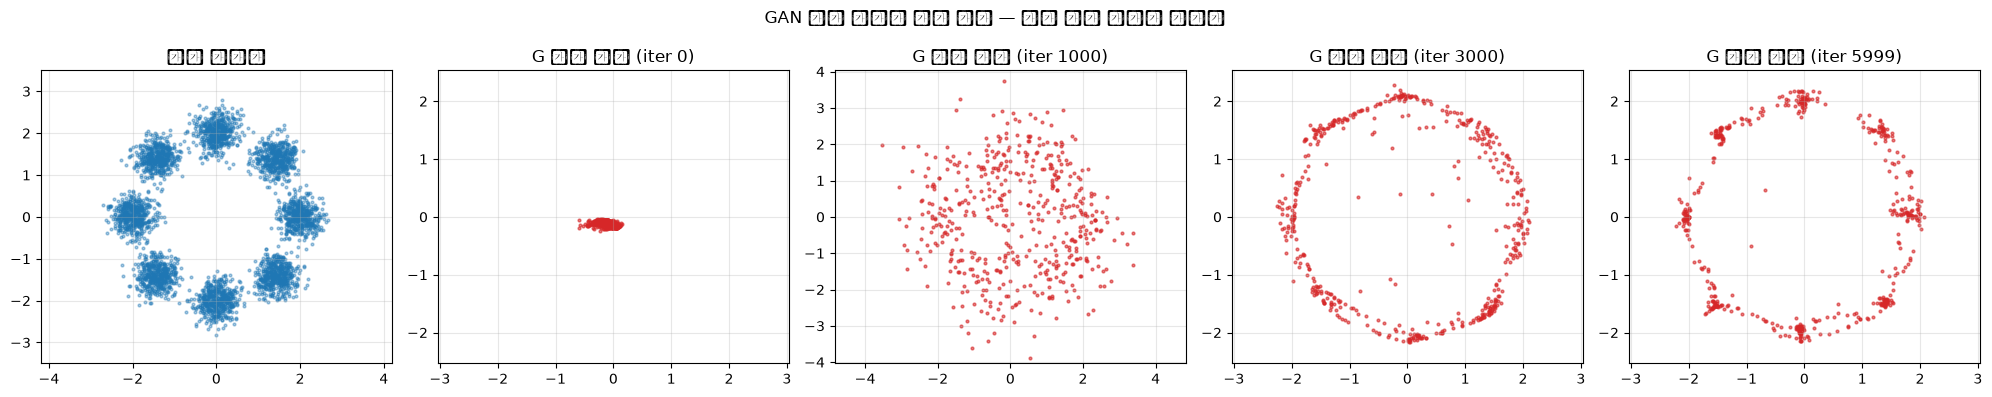

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].scatter(data[:, 0], data[:, 1], s=4, alpha=0.4, c="tab:blue")
axes[0].set_title("실제 데이터"); axes[0].axis("equal")
for ax, it in zip(axes[1:], [0, 1000, 3000, ITERS - 1]):
    ax.scatter(snapshots[it][:, 0], snapshots[it][:, 1], s=4, alpha=0.6, c="tab:red")
    ax.set_title(f"G 생성 샘플 (iter {it})"); ax.axis("equal")
for ax in axes:
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.grid(alpha=0.3)
plt.suptitle("GAN 생성 샘플의 변화 과정 — 점점 실제 분포와 닮아감")
plt.tight_layout(); plt.show()


## ✅ 정리

- GAN은 **두 네트워크의 경쟁**으로 학습: D는 진짜/가짜를 구분, G는 D를 속이는 샘플 생성
- закрыный 형태의 손실(비포화 손실)을 쓰면 초반 학습이 안정적: `log D(G(z))`를 최소화 (여기선 BCEWithLogits로 동일 효과)
-응용: 초고해상도 이미지 생성, 이미지 변환( CycleGAN ), 텍스트→이미지 (DALL-E 등), 데이터 증강
- 주의: **mode collapse**(일부 모드만 생성), 학습 불안정 → Wasserstein GAN(WGAN), gradient penalty 등으로 개선
- 다음: [`08_Transformer.ipynb`](./08_Transformer.ipynb) — 어텐션이 전부다, Transformer
